In [6]:
import os
ROOT = os.path.abspath("../../../..")  # repo root

files_3t15t_20_steps = f"{ROOT}/results/latent_tta_20_steps/pmri_threet-to-onepointfivet_dice_predictor-adversarial-location-concentration_beta-cleanHalf_"
files_15t3t_20_steps = f"{ROOT}/results/latent_tta_20_steps/pmri_onepointfivet-to-threet_dice_predictor-adversarial-location-concentration_beta-cleanHalf_"
files_promise12_20_steps = f"{ROOT}/results/latent_tta_20_steps/pmri_promise12_dice_predictor-adversarial-location-concentration_beta-cleanHalf_"

files_3t15t_100_steps = f"{ROOT}/results/latent_tta_100_steps/pmri_threet-to-onepointfivet_dice_predictor-adversarial-location-concentration_beta-cleanHalf_"
files_15t3t_100_steps = f"{ROOT}/results/latent_tta_100_steps/pmri_onepointfivet-to-threet_dice_predictor-adversarial-location-concentration_beta-cleanHalf_"
files_promise12_100_steps = f"{ROOT}/results/latent_tta_100_steps/pmri_promise12_dice_predictor-adversarial-location-concentration_beta-cleanHalf_"

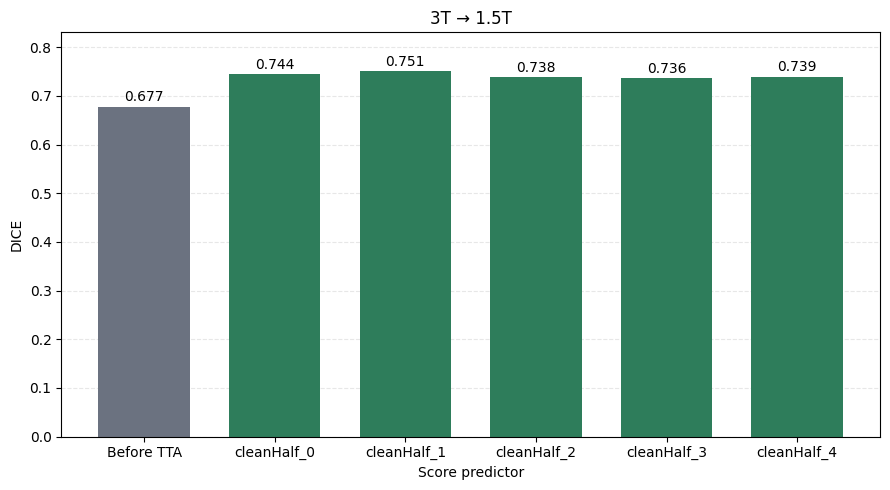

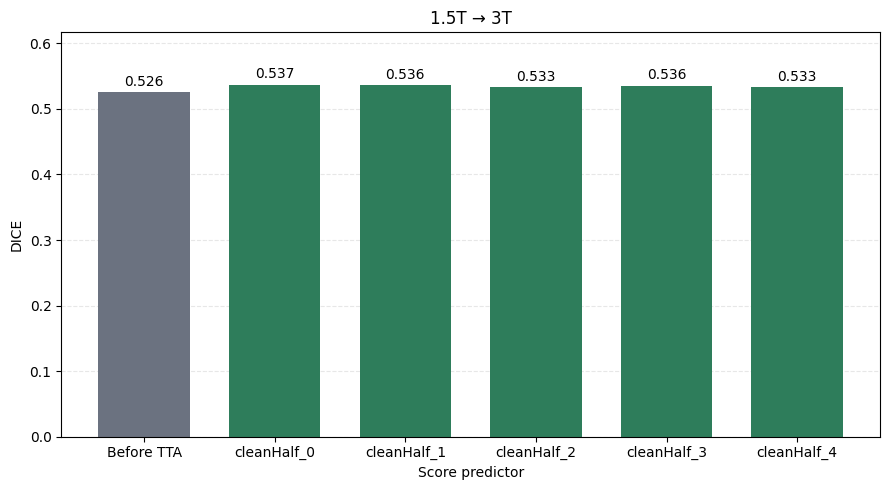

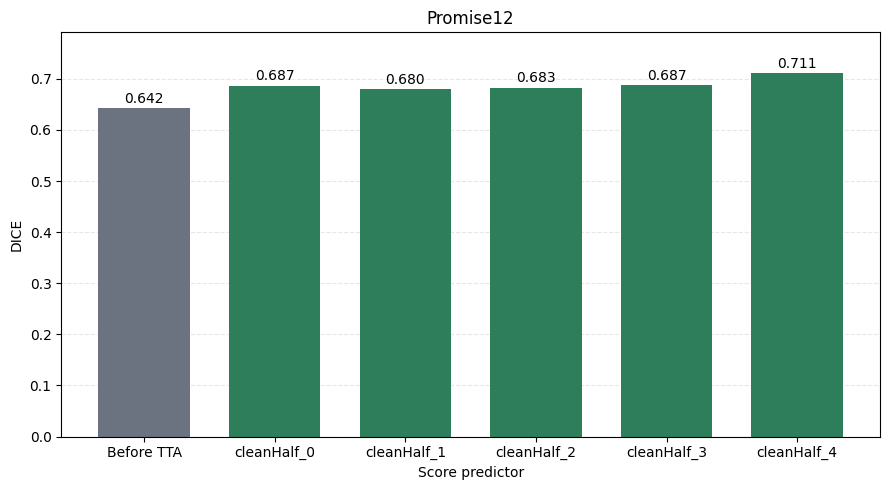

In [ ]:
import glob
import pickle
import numpy as np
import matplotlib.pyplot as plt


def load_results(base_path, evaluation_key):
    dice_before = []
    dice_after = []

    for x in range(5):
        matches = glob.glob(f"{base_path}{x}*/latent_tta.pkl")

        if not matches:
            raise FileNotFoundError(
                f"No result found for cleanHalf_{x} in:\n{base_path}{x}*/latent_tta.pkl"
            )

        if len(matches) > 1:
            print(f"Warning: multiple matches for cleanHalf_{x}:")
            for match in matches:
                print(f"  {match}")

        path = matches[0]

        with open(path, "rb") as f:
            data = pickle.load(f)

        evaluation = data["evaluation"][evaluation_key]

        dice_before.append(evaluation["dice_before"].mean())
        dice_after.append(evaluation["dice_after"].mean())

    return np.array(dice_before), np.array(dice_after)


# ------------------------------------------------------------
# Load all results
# ------------------------------------------------------------

before_3t15t, after_3t15t = load_results(
    files_3t15t,
    "threet-to-onepointfivet_test"
)

before_15t3t, after_15t3t = load_results(
    files_15t3t,
    "onepointfivet-to-threet_test"
)

before_promise12, after_promise12 = load_results(
    files_promise12,
    "promise12_test"
)


# ------------------------------------------------------------
# Print results
# ------------------------------------------------------------

# print("3T -> 1.5T")
# for x in range(5):
#     print(f"cleanHalf_{x}")
#     print(f"DICE before: {before_3t15t[x]:.3f}")
#     print(f"DICE after:  {after_3t15t[x]:.3f}")
#     print(f"Delta DICE:  {after_3t15t[x] - before_3t15t[x]:.3f}")
#     print()

# print("================================")
# print()

# print("1.5T -> 3T")
# for x in range(5):
#     print(f"cleanHalf_{x}")
#     print(f"DICE before: {before_15t3t[x]:.3f}")
#     print(f"DICE after:  {after_15t3t[x]:.3f}")
#     print(f"Delta DICE:  {after_15t3t[x] - before_15t3t[x]:.3f}")
#     print()

# print("================================")
# print()

# print("Promise12")
# for x in range(5):
#     print(f"cleanHalf_{x}")
#     print(f"DICE before: {before_promise12[x]:.3f}")
#     print(f"DICE after:  {after_promise12[x]:.3f}")
#     print(f"Delta DICE:  {after_promise12[x] - before_promise12[x]:.3f}")
#     print()


# ------------------------------------------------------------
# Plotting
# ------------------------------------------------------------

def plot_dice(before, after, title):
    labels = ["Before TTA"] + [f"cleanHalf_{i}" for i in range(5)]
    values = [before[0]] + list(after)

    baseline = before[0]

    colors = (
        ["#6B7280"] +  # baseline
        ["#2E7D5B" if value >= baseline else "#C45A5A" for value in after]
    )

    x = np.arange(len(labels))

    fig, ax = plt.subplots(figsize=(9, 5))

    bars = ax.bar(
        x,
        values,
        color=colors,
        width=0.7
    )

    ax.set_xlabel("Score predictor")
    ax.set_ylabel("DICE")
    ax.set_title(title)

    ax.set_xticks(x)
    ax.set_xticklabels(labels)

    ax.grid(
        axis="y",
        linestyle="--",
        alpha=0.3
    )
    ax.set_axisbelow(True)

    # Add values above bars
    for bar, value in zip(bars, values):
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            value + 0.005,
            f"{value:.3f}",
            ha="center",
            va="bottom",
            fontsize=10
        )

    ax.set_ylim(0, max(values) + 0.08)

    plt.tight_layout()
    plt.show()


plot_dice(
    before_3t15t,
    after_3t15t,
    "3T → 1.5T"
)

plot_dice(
    before_15t3t,
    after_15t3t,
    "1.5T → 3T"
)

plot_dice(
    before_promise12,
    after_promise12,
    "Promise12"
)

3T -> 1.5T
cleanHalf_0
  20 steps:  DICE before = 0.677,  DICE after = 0.744,  Delta DICE = +0.067
  100 steps:  DICE before = 0.677,  DICE after = 0.754,  Delta DICE = +0.076

cleanHalf_1
  20 steps:  DICE before = 0.677,  DICE after = 0.751,  Delta DICE = +0.073
  100 steps:  DICE before = 0.677,  DICE after = 0.750,  Delta DICE = +0.073

cleanHalf_2
  20 steps:  DICE before = 0.677,  DICE after = 0.738,  Delta DICE = +0.061
  100 steps:  DICE before = 0.677,  DICE after = 0.738,  Delta DICE = +0.061

cleanHalf_3
  20 steps:  DICE before = 0.677,  DICE after = 0.736,  Delta DICE = +0.059
  100 steps:  DICE before = 0.677,  DICE after = 0.737,  Delta DICE = +0.060

cleanHalf_4
  20 steps:  DICE before = 0.677,  DICE after = 0.739,  Delta DICE = +0.062
  100 steps:  DICE before = 0.677,  DICE after = 0.739,  Delta DICE = +0.062


1.5T -> 3T
cleanHalf_0
  20 steps:  DICE before = 0.526,  DICE after = 0.537,  Delta DICE = +0.011
  100 steps:  DICE before = 0.526,  DICE after = 0.537,  De

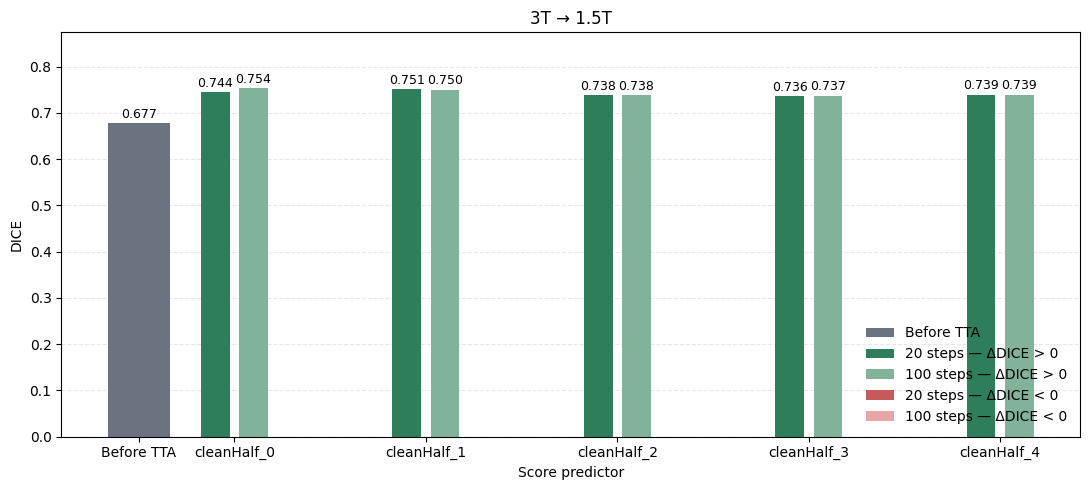

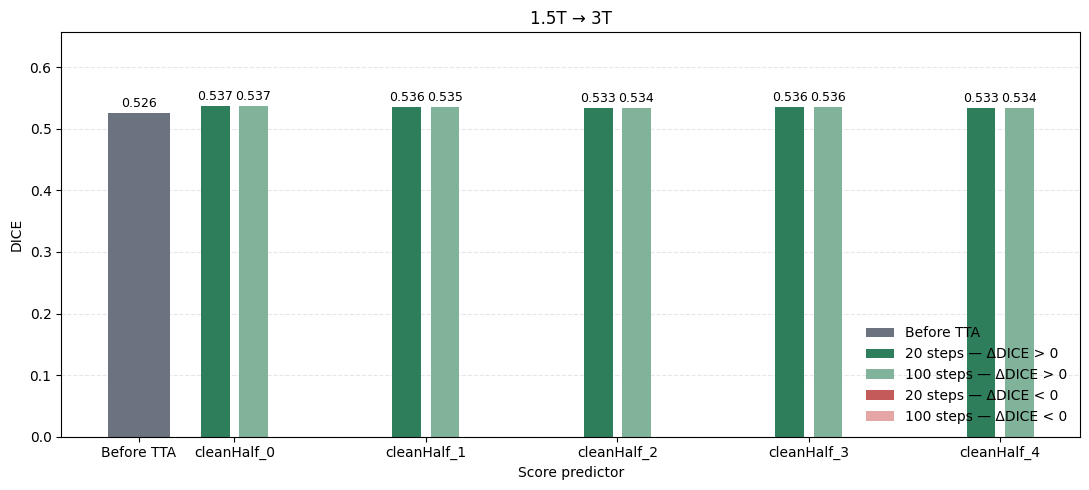

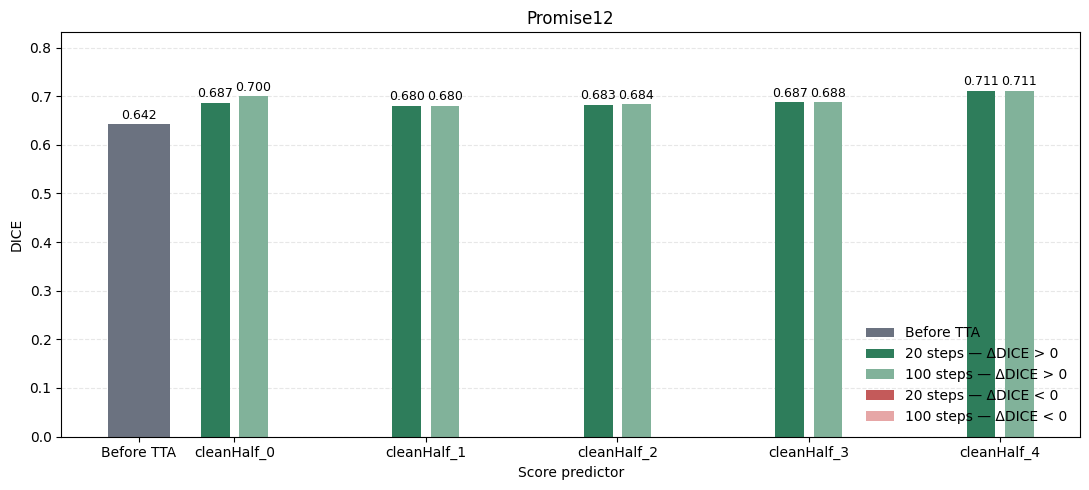

In [10]:
import glob
import os
import pickle
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

ROOT = os.path.abspath("../../../..")  # repo root


# ============================================================
# File paths
# ============================================================

files_3t15t_20_steps = (
    f"{ROOT}/"
    "results/latent_tta_20_steps/"
    "pmri_threet-to-onepointfivet_dice_predictor-adversarial-location-concentration_beta-cleanHalf_"
)

files_15t3t_20_steps = (
    f"{ROOT}/"
    "results/latent_tta_20_steps/"
    "pmri_onepointfivet-to-threet_dice_predictor-adversarial-location-concentration_beta-cleanHalf_"
)

files_promise12_20_steps = (
    f"{ROOT}/"
    "results/latent_tta_20_steps/"
    "pmri_promise12_dice_predictor-adversarial-location-concentration_beta-cleanHalf_"
)

files_3t15t_100_steps = (
    f"{ROOT}/"
    "results/latent_tta_100_steps/"
    "pmri_threet-to-onepointfivet_dice_predictor-adversarial-location-concentration_beta-cleanHalf_"
)

files_15t3t_100_steps = (
    f"{ROOT}/"
    "results/latent_tta_100_steps/"
    "pmri_onepointfivet-to-threet_dice_predictor-adversarial-location-concentration_beta-cleanHalf_"
)

files_promise12_100_steps = (
    f"{ROOT}/"
    "results/latent_tta_100_steps/"
    "pmri_promise12_dice_predictor-adversarial-location-concentration_beta-cleanHalf_"
)


# ============================================================
# Load results
# ============================================================

def load_results(base_path, evaluation_key):
    dice_before = []
    dice_after = []
    delta_dice = []

    for x in range(5):

        matches = glob.glob(
            f"{base_path}{x}*/latent_tta.pkl"
        )

        if not matches:
            raise FileNotFoundError(
                f"No result found for cleanHalf_{x}:\n"
                f"{base_path}{x}*/latent_tta.pkl"
            )

        if len(matches) > 1:
            print(f"Warning: multiple matches for cleanHalf_{x}:")
            for match in matches:
                print(f"  {match}")

        path = matches[0]

        with open(path, "rb") as f:
            data = pickle.load(f)

        evaluation = data["evaluation"][evaluation_key]

        dice_before.append(
            evaluation["dice_before"].mean()
        )

        dice_after.append(
            evaluation["dice_after"].mean()
        )

        # Read Delta DICE directly from pickle
        delta_dice.append(
            evaluation["delta_dice"]
        )

    return (
        np.array(dice_before),
        np.array(dice_after),
        np.array(delta_dice)
    )


# ============================================================
# Load all datasets
# ============================================================

# 3T -> 1.5T
before_3t15t_20, after_3t15t_20, delta_3t15t_20 = load_results(
    files_3t15t_20_steps,
    "threet-to-onepointfivet_test"
)

before_3t15t_100, after_3t15t_100, delta_3t15t_100 = load_results(
    files_3t15t_100_steps,
    "threet-to-onepointfivet_test"
)


# 1.5T -> 3T
before_15t3t_20, after_15t3t_20, delta_15t3t_20 = load_results(
    files_15t3t_20_steps,
    "onepointfivet-to-threet_test"
)

before_15t3t_100, after_15t3t_100, delta_15t3t_100 = load_results(
    files_15t3t_100_steps,
    "onepointfivet-to-threet_test"
)


# Promise12
before_promise12_20, after_promise12_20, delta_promise12_20 = load_results(
    files_promise12_20_steps,
    "promise12_test"
)

before_promise12_100, after_promise12_100, delta_promise12_100 = load_results(
    files_promise12_100_steps,
    "promise12_test"
)


# ============================================================
# Print results
# ============================================================

def print_results(
    name,
    before_20,
    after_20,
    delta_20,
    before_100,
    after_100,
    delta_100
):
    print(name)

    for x in range(5):
        print(f"cleanHalf_{x}")

        print(
            f"  20 steps:"
            f"  DICE before = {before_20[x]:.3f},"
            f"  DICE after = {after_20[x]:.3f},"
            f"  Delta DICE = {delta_20[x]:+.3f}"
        )

        print(
            f"  100 steps:"
            f"  DICE before = {before_100[x]:.3f},"
            f"  DICE after = {after_100[x]:.3f},"
            f"  Delta DICE = {delta_100[x]:+.3f}"
        )

        print()


print_results(
    "3T -> 1.5T",
    before_3t15t_20,
    after_3t15t_20,
    delta_3t15t_20,
    before_3t15t_100,
    after_3t15t_100,
    delta_3t15t_100
)

print("================================")
print()

print_results(
    "1.5T -> 3T",
    before_15t3t_20,
    after_15t3t_20,
    delta_15t3t_20,
    before_15t3t_100,
    after_15t3t_100,
    delta_15t3t_100
)

print("================================")
print()

print_results(
    "Promise12",
    before_promise12_20,
    after_promise12_20,
    delta_promise12_20,
    before_promise12_100,
    after_promise12_100,
    delta_promise12_100
)


# ============================================================
# Plotting
# ============================================================

def plot_dice(
    before_20,
    after_20,
    delta_20,
    before_100,
    after_100,
    delta_100,
    title
):
    # The baseline is identical for all predictors
    baseline = before_20[0]

    # --------------------------------------------------------
    # Positions
    # --------------------------------------------------------

    x_baseline = 0

    # One position per cleanHalf
    x_groups = np.arange(1, 11, 2)

    width = 0.30
    gap = 0.10

    fig, ax = plt.subplots(figsize=(11, 5))

    # --------------------------------------------------------
    # Colors
    # --------------------------------------------------------

    baseline_color = "#6B7280"

    # Positive Delta DICE
    green_20 = "#2E7D5B"
    green_100 = "#81B29A"

    # Negative Delta DICE
    red_20 = "#C45A5A"
    red_100 = "#E6A6A6"

    # --------------------------------------------------------
    # Baseline
    # --------------------------------------------------------

    baseline_bar = ax.bar(
        x_baseline,
        baseline,
        width=0.65,
        color=baseline_color
    )

    # --------------------------------------------------------
    # 20-step bars
    # --------------------------------------------------------

    colors_20 = [
        green_20 if delta >= 0 else red_20
        for delta in delta_20
    ]

    bars_20 = ax.bar(
        x_groups - width / 2 - gap / 2,
        after_20,
        width=width,
        color=colors_20
    )

    # --------------------------------------------------------
    # 100-step bars
    # --------------------------------------------------------

    colors_100 = [
        green_100 if delta >= 0 else red_100
        for delta in delta_100
    ]

    bars_100 = ax.bar(
        x_groups + width / 2 + gap / 2,
        after_100,
        width=width,
        color=colors_100
    )

    # --------------------------------------------------------
    # Axes
    # --------------------------------------------------------

    ax.set_xlabel("Score predictor")
    ax.set_ylabel("DICE")
    ax.set_title(title)

    ax.set_xticks(
        [x_baseline] + list(x_groups)
    )

    ax.set_xticklabels(
        ["Before TTA"] +
        [f"cleanHalf_{i}" for i in range(5)]
    )

    # --------------------------------------------------------
    # Grid
    # --------------------------------------------------------

    ax.grid(
        axis="y",
        linestyle="--",
        alpha=0.3
    )

    ax.set_axisbelow(True)

    # --------------------------------------------------------
    # Baseline value
    # --------------------------------------------------------

    ax.text(
        x_baseline,
        baseline + 0.005,
        f"{baseline:.3f}",
        ha="center",
        va="bottom",
        fontsize=9
    )

    # --------------------------------------------------------
    # DICE + Delta DICE labels
    # --------------------------------------------------------

    for i, (bar20, bar100) in enumerate(zip(bars_20, bars_100)):

        dice20 = after_20[i]
        dice100 = after_100[i]

        delta20 = delta_20[i]
        delta100 = delta_100[i]

        # ---- 20 steps ----

        x20 = bar20.get_x() + bar20.get_width() / 2

        ax.text(
            x20,
            dice20 + 0.005,
            f"{dice20:.3f}",
            ha="center",
            va="bottom",
            fontsize=9
        )

        # ax.text(
        #     x20,
        #     dice20 + 0.025,
        #     f"Δ {delta20:+.3f}",
        #     ha="center",
        #     va="bottom",
        #     fontsize=7.5
        # )

        # ---- 100 steps ----

        x100 = bar100.get_x() + bar100.get_width() / 2

        ax.text(
            x100,
            dice100 + 0.005,
            f"{dice100:.3f}",
            ha="center",
            va="bottom",
            fontsize=9
        )

        # ax.text(
        #     x100,
        #     dice100 + 0.045,
        #     f"Δ {delta100:+.3f}",
        #     ha="center",
        #     va="bottom",
        #     fontsize=7.5
        # )

    # --------------------------------------------------------
    # Legend
    # --------------------------------------------------------

    legend_elements = [
        Patch(
            facecolor=baseline_color,
            label="Before TTA"
        ),
        Patch(
            facecolor=green_20,
            label="20 steps — ΔDICE > 0"
        ),
        Patch(
            facecolor=green_100,
            label="100 steps — ΔDICE > 0"
        ),
        Patch(
            facecolor=red_20,
            label="20 steps — ΔDICE < 0"
        ),
        Patch(
            facecolor=red_100,
            label="100 steps — ΔDICE < 0"
        ),
    ]

    ax.legend(
        handles=legend_elements,
        frameon=False
    )

    # --------------------------------------------------------
    # Y-axis limit
    # --------------------------------------------------------

    max_value = max(
        baseline,
        after_20.max(),
        after_100.max()
    )

    ax.set_ylim(
        0,
        max_value + 0.12
    )

    plt.tight_layout()
    plt.show()


# ============================================================
# Generate plots
# ============================================================

plot_dice(
    before_3t15t_20,
    after_3t15t_20,
    delta_3t15t_20,
    before_3t15t_100,
    after_3t15t_100,
    delta_3t15t_100,
    "3T → 1.5T"
)

plot_dice(
    before_15t3t_20,
    after_15t3t_20,
    delta_15t3t_20,
    before_15t3t_100,
    after_15t3t_100,
    delta_15t3t_100,
    "1.5T → 3T"
)

plot_dice(
    before_promise12_20,
    after_promise12_20,
    delta_promise12_20,
    before_promise12_100,
    after_promise12_100,
    delta_promise12_100,
    "Promise12"
)